# Tutorial 2 — WorldView-3, Los Peñasquitos Canyon

> Reading this on the docs site? To run it, [open a Codespace](https://stereopipeline-quickstart.readthedocs.io/en/latest/start/codespaces.html): ASP and `asp-plot` are already installed there.

Two WorldView-3 images of Los Peñasquitos Canyon, a nature preserve on the north edge of San Diego a few kilometers inland from UC San Diego, taken ten weeks apart from different angles. At 0.3 m per pixel these images are far sharper than ASTER's 15 m, so this tutorial keeps the full resolution and works on a 1 km square of the canyon, where steep spurs and gullies of chaparral run down to a creek and the trails along it. It makes a 1 m DEM, in about 12 minutes.

> To run it, click **Run All** at the top, then scroll down to follow it: each step shows its progress while it runs, then its results.
> ![The top of the window: the notebook's toolbar, with the Run All button boxed](../start/figures/run-all.png)

| Image | Date | Looking |
|---|---|---|
| `104001000496A100` | 2014-11-09 | 1.1° from straight down |
| `10400100071D8800` | 2015-01-24 | 16.3° to the side |

The steps:

1. Download the two images.
2. Look at the viewing geometry.
3. Orthorectify the images onto a coarse map of the terrain.
4. Run stereo matching and build the DEM.
5. Make a PDF report, with a comparison against ICESat-2.
6. Download the results.

In [1]:
from pathlib import Path

from utils import run, run_stereo, timer

DATA = "../data/ucsd_penasquitos"
LOGS = f"{DATA}/logs"

!mkdir -p {DATA}

# The study area, xmin ymin xmax ymax in UTM zone 11N (EPSG:32611) meters:
# a 1 km square at the west end of Los Peñasquitos Canyon.
T_SRS = "EPSG:32611"
T_PROJWIN = "480420 3641720 481420 3642720"

# Pixel size of the orthorectified images, in meters: close to the images' own
# 0.31 m, and 1000 m / 0.3125 m = 3200 pixels exactly, which stereo splits into
# four 1600-pixel tiles, run one after another so the map fills in tile by tile.
GSD = 0.3125
TILE = 1600

# Pixel size of the DEM, in meters.
DEM_RES = 1.0

# The Copernicus reference DEM, fetched by the download step.
REF_DEM = f"{DATA}/ref/cop30_penasquitos.tif"

SCENES = ["104001000496A100", "10400100071D8800"]   # left, right

# ICESat-2 points and figure selections shipped with this tutorial, fetched by
# the download step. The report replays them with --reuse-selections, so no
# SlideRule request is made. Set FRESH_ICESAT2 = True to request fresh
# ICESat-2 data from SlideRule instead.
FRESH_ICESAT2 = False
SHIPPED_SELECTIONS = f"{DATA}/icesat2_shipped/pair_figure_selections.yml"

## 1. Download the images

Each image is about 870 MB, with a file describing its camera. They are IARPA CORE3D data, released for public research; publications that use them should cite Hagstrom et al. (2021), "Cumulative assessment for urban 3D modeling" (IEEE IGARSS).

> About 2 minutes.

In [2]:
run(f"bash ../scripts/download_worldview_ucsd.sh {DATA} {' '.join(SCENES)}", log=f"{LOGS}/download.log", label="Downloading the images")

bash ../scripts/download_worldview_ucsd.sh ../data/ucsd_penasquitos 104001000496A100 10400100071D8800


✅ **Downloading the images**: done in 1 min 01 s. Full log: `../data/ucsd_penasquitos/logs/download.log`

## 2. Viewing geometry

[More on viewing geometry](https://stereopipeline-quickstart.readthedocs.io/en/latest/concepts/stereo-photogrammetry.html#viewing-geometry).

> About half a minute.

✅ **Plotting the stereo geometry**: done in 8 s

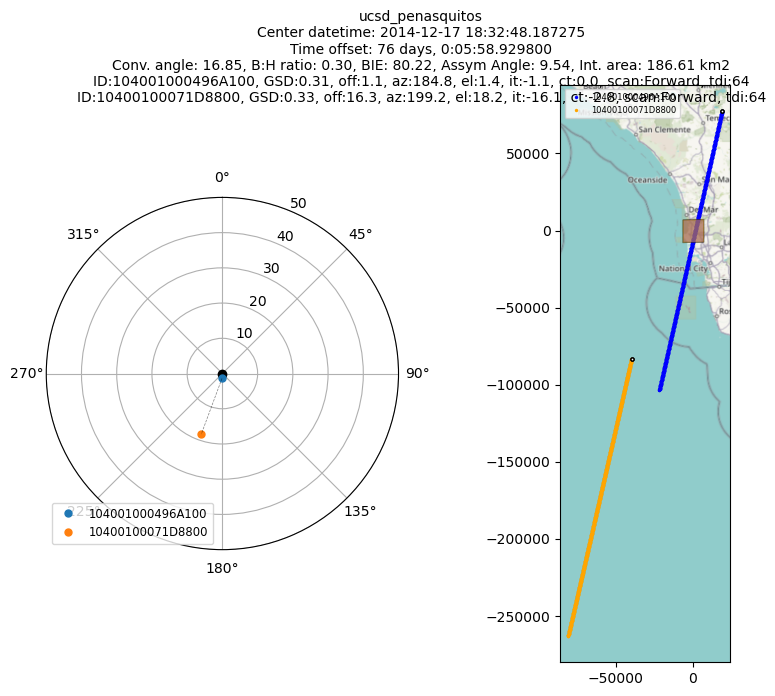

In [3]:
with timer("Plotting the stereo geometry"):
    import contextily
    from asp_plot.stereo_geometry import StereoGeometryPlotter

    # The map tiles were fetched when the Codespace was built
    # (scripts/prefetch_basemap.py); without them, this fetches them itself.
    contextily.set_cache_dir("../data/basemap_cache")

    geometry = StereoGeometryPlotter(inputs=[f"{DATA}/{catid}_P001.xml" for catid in SCENES])
    geometry.stereo_geom_plot()

Left, a skyplot: each dot is the direction the satellite looked from, as seen from the ground. One image looked almost straight down, the other from 16° to the side. Right, the two image footprints on a map; each covers about 13 × 14 km, and we use a small piece of the overlap.

## 3. Orthorectify

The full images are about 43,000 × 45,000 pixels. ASP's `mapproject` reads just the study area out of each one and drapes it over the Copernicus 30 m reference DEM, so that both sit on the same map grid, north up, at 0.3125 m per pixel. [Why orthorectify first](https://stereopipeline-quickstart.readthedocs.io/en/latest/concepts/orthorectification.html).

> About half a minute per image.

In [4]:
Path(f"{DATA}/ortho").mkdir(exist_ok=True)
for catid in SCENES:
    out = f"{DATA}/ortho/{catid}.tif"
    if Path(out).exists():
        print(f"{out} exists — skipping mapproject. Delete it to reprocess.")
    else:
        run(f"""
            mapproject -t dg --threads 4 --t_srs {T_SRS} --tr {GSD} --t_projwin {T_PROJWIN} \
                {REF_DEM} {DATA}/{catid}_P001.NTF {DATA}/{catid}_P001.xml {out}
            """,
            log=f"{LOGS}/mapproject_{catid}.log",
            label=f"Orthorectifying {catid}",
        )

!ls -lh {DATA}/ortho/*.tif

mapproject -t dg --threads 4 --t_srs EPSG:32611 --tr 0.3125 --t_projwin 480420 3641720 481420 3642720 ../data/ucsd_penasquitos/ref/cop30_penasquitos.tif ../data/ucsd_penasquitos/104001000496A100_P001.NTF ../data/ucsd_penasquitos/104001000496A100_P001.xml ../data/ucsd_penasquitos/ortho/104001000496A100.tif


✅ **Orthorectifying 104001000496A100**: done in 12 s. Full log: `../data/ucsd_penasquitos/logs/mapproject_104001000496A100.log`

mapproject -t dg --threads 4 --t_srs EPSG:32611 --tr 0.3125 --t_projwin 480420 3641720 481420 3642720 ../data/ucsd_penasquitos/ref/cop30_penasquitos.tif ../data/ucsd_penasquitos/10400100071D8800_P001.NTF ../data/ucsd_penasquitos/10400100071D8800_P001.xml ../data/ucsd_penasquitos/ortho/10400100071D8800.tif


✅ **Orthorectifying 10400100071D8800**: done in 12 s. Full log: `../data/ucsd_penasquitos/logs/mapproject_10400100071D8800.log`

-rw-r--r--  1 ben  staff    42M Oct 30 12:29 ../data/ucsd_penasquitos/ortho/104001000496A100.tif
-rw-r--r--  1 ben  staff    42M Oct 30 12:29 ../data/ucsd_penasquitos/ortho/10400100071D8800.tif


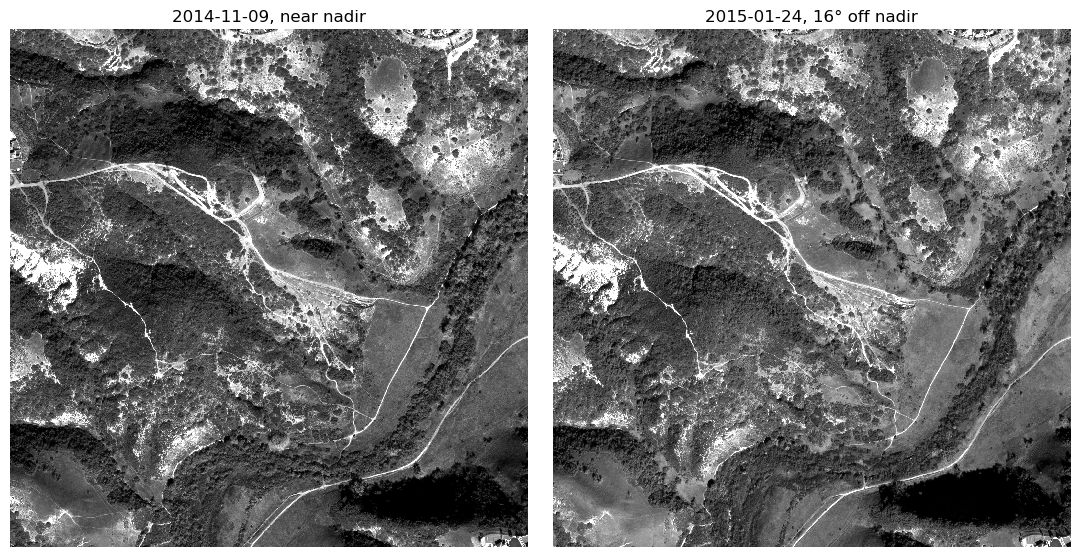

In [5]:
from utils import show_image_pair

show_image_pair(f"{DATA}/ortho/{SCENES[0]}.tif", f"{DATA}/ortho/{SCENES[1]}.tif",
                ("2014-11-09, near nadir", "2015-01-24, 16° off nadir"), downsample=2)

The study area in both images, on one map grid with north up. The canyon runs from the bottom left to the top right, with steep spurs and gullies on both sides and a creek, trees and a dirt track along its floor, and the flat valley floor at the right edge. The second image looked from the side and was taken in January with the sun lower, so slopes and shadows look different. The two line up closely; what still differs between them is what stereo measures: the heights of the trees and terrain that the coarse reference DEM smooths over.

## 4. Stereo matching and the DEM

ASP's `parallel_stereo` finds, for every pixel, where the same spot appears in the other image, and turns each match into a height. `point2dem` then grids the heights into a DEM with 1 m pixels. [How matching works](https://stereopipeline-quickstart.readthedocs.io/en/latest/concepts/stereo-photogrammetry.html).

While it runs, the cell first shows the features it matched between the two images, then a map of the area, divided into the tiles stereo works through (dashed lines), which fills in as each tile finishes: the offsets between the two images, east-west and north-south, and then the heights that come out of them.

> About 7 minutes.

parallel_stereo --stereo-algorithm asp_mgm --subpixel-mode 9 --cost-mode 3 --job-size-w 1600 --job-size-h 1600 --processes 1 --threads-multiprocess 4 --threads-singleprocess 4 ../data/ucsd_penasquitos/ortho/104001000496A100.tif ../data/ucsd_penasquitos/ortho/10400100071D8800.tif ../data/ucsd_penasquitos/104001000496A100_P001.xml ../data/ucsd_penasquitos/10400100071D8800_P001.xml ../data/ucsd_penasquitos/stereo/run ../data/ucsd_penasquitos/ref/cop30_penasquitos.tif


✅ **Height (m)**: done in 3 min 33 s. Full log: `../data/ucsd_penasquitos/logs/parallel_stereo.log`

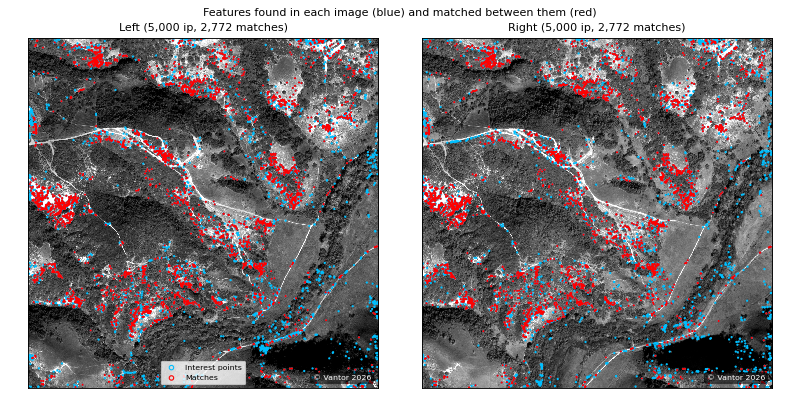

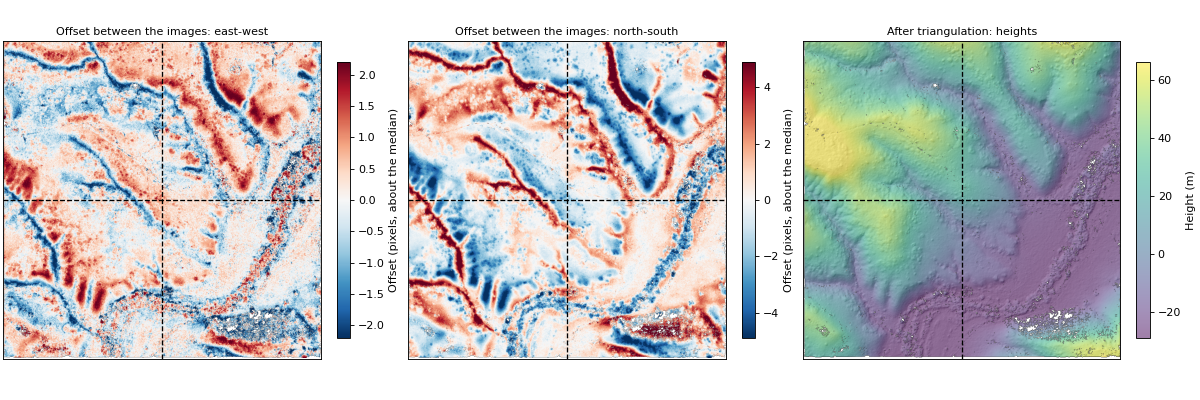

point2dem --threads 4 --tr 1.0 --t_srs EPSG:32611 --errorimage ../data/ucsd_penasquitos/stereo/run-PC.tif


✅ **Gridding the points into a DEM**: done in 6 s. Full log: `../data/ucsd_penasquitos/logs/point2dem.log`

-rw-r--r--  1 ben  staff   1.8M Oct 30 12:33 ../data/ucsd_penasquitos/stereo/run-DEM.tif


In [6]:
if Path(f"{DATA}/stereo/run-DEM.tif").exists():
    print(f"{DATA}/stereo/run-DEM.tif exists — skipping stereo. Delete {DATA}/stereo/ to reprocess.")
else:
    run_stereo(f"""
        parallel_stereo \
            --stereo-algorithm asp_mgm --subpixel-mode 9 --cost-mode 3 \
            --job-size-w {TILE} --job-size-h {TILE} \
            --processes 1 --threads-multiprocess 4 --threads-singleprocess 4 \
            {DATA}/ortho/{SCENES[0]}.tif {DATA}/ortho/{SCENES[1]}.tif \
            {DATA}/{SCENES[0]}_P001.xml {DATA}/{SCENES[1]}_P001.xml \
            {DATA}/stereo/run {REF_DEM}
        """,
        prefix=f"{DATA}/stereo/run",
        log=f"{LOGS}/parallel_stereo.log",
    )
    run(
        f"point2dem --threads 4 --tr {DEM_RES} --t_srs {T_SRS} --errorimage {DATA}/stereo/run-PC.tif",
        log=f"{LOGS}/point2dem.log",
        label="Gridding the points into a DEM",
    )

!ls -lh {DATA}/stereo/run-DEM.tif

Above, the features found in each image (blue) and the ones matched between them (red); stereo uses these to decide where to search. Below, the offset between the two input images at every pixel, split into its east-west and north-south parts. This is [relief displacement](https://stereopipeline-quickstart.readthedocs.io/en/latest/concepts/orthorectification.html): the two views look from different directions, so the same tree, boulder or hillside sits in a slightly different place in each image, by an amount that depends on its height. Any error left in the cameras adds a shift that is the same everywhere, so the maps show the offsets about their median: red one way, blue the other. The offsets are small, because orthorectification already removed most of the displacement; stereo measures what is left. Right, the heights triangulated from those offsets, as a hillshade with elevation in color.

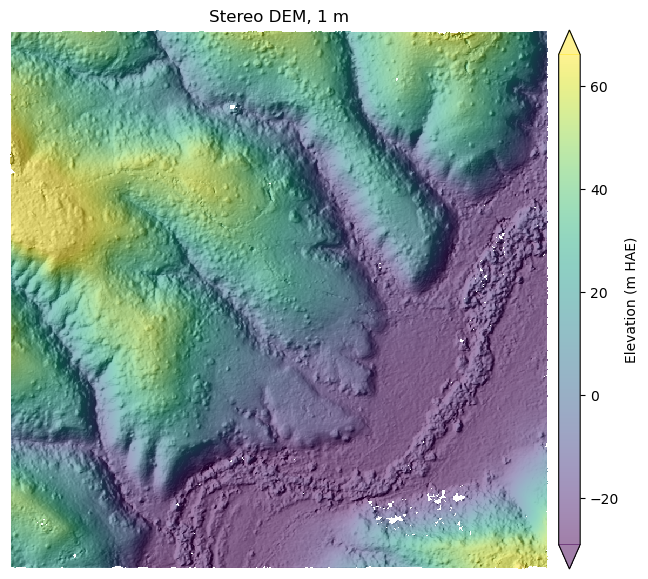

In [7]:
from utils import show_dem_hillshade

show_dem_hillshade(f"{DATA}/stereo/run-DEM.tif", title="Stereo DEM, 1 m", hillshade_fn=f"{DATA}/stereo/run-DEM_hs.tif")

The DEM as a hillshade, lit from several directions at once so every slope shows, with elevation in color. At one meter per pixel, single trees, the track along the creek and the trails up the spurs stand out, and every gully between the spurs is resolved. The ground rises about 100 m from the creek to the ridge tops. Small white patches are places stereo could not match: in the trees along the creek, and in a few deep shadows. Heights are above the WGS84 ellipsoid, which here is about 35 m below sea level.

## 5. Report

`asp_report`, from `asp-plot`, writes a PDF with everything about the run: the images, the viewing geometry, the matches, the DEM, and how it compares with the reference map and with [ICESat-2](https://stereopipeline-quickstart.readthedocs.io/en/latest/concepts/alignment.html), a satellite that measures heights directly with a laser. The vendor's camera descriptions put the whole DEM about 10 m low, so the report ends by shifting it onto the ICESat-2 points with `pc_align`. [What's in the report](https://stereopipeline-quickstart.readthedocs.io/en/latest/concepts/visualization.html). Three of its figures appear below.

> About a minute.

asp_report --directory ../data/ucsd_penasquitos --stereo-directory stereo --reference-dem ../data/ucsd_penasquitos/ref/cop30_penasquitos.tif --subset-km 0.25 --pc-align-min-points 150 --reuse-selections ../data/ucsd_penasquitos/icesat2_shipped/pair_figure_selections.yml --figures-directory ../data/ucsd_penasquitos/stereo/report_figures --report-filename penasquitos_wv3_report.pdf


✅ **Making the report**: done in 20 s. Full log: `../data/ucsd_penasquitos/logs/asp_report.log`

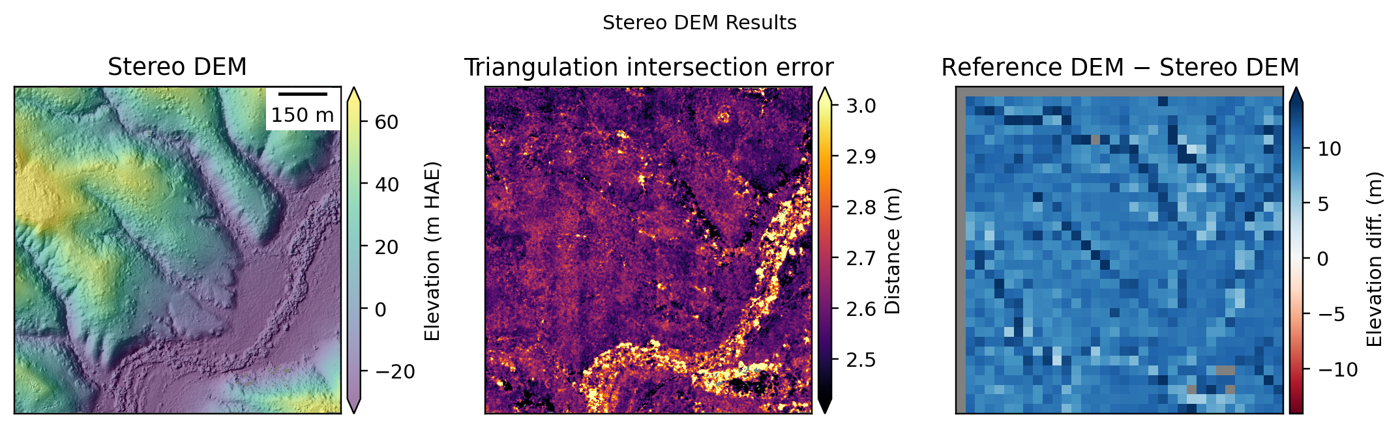

**Report figure 5.** The DEM, its triangulation intersection error, and its difference from the reference DEM.

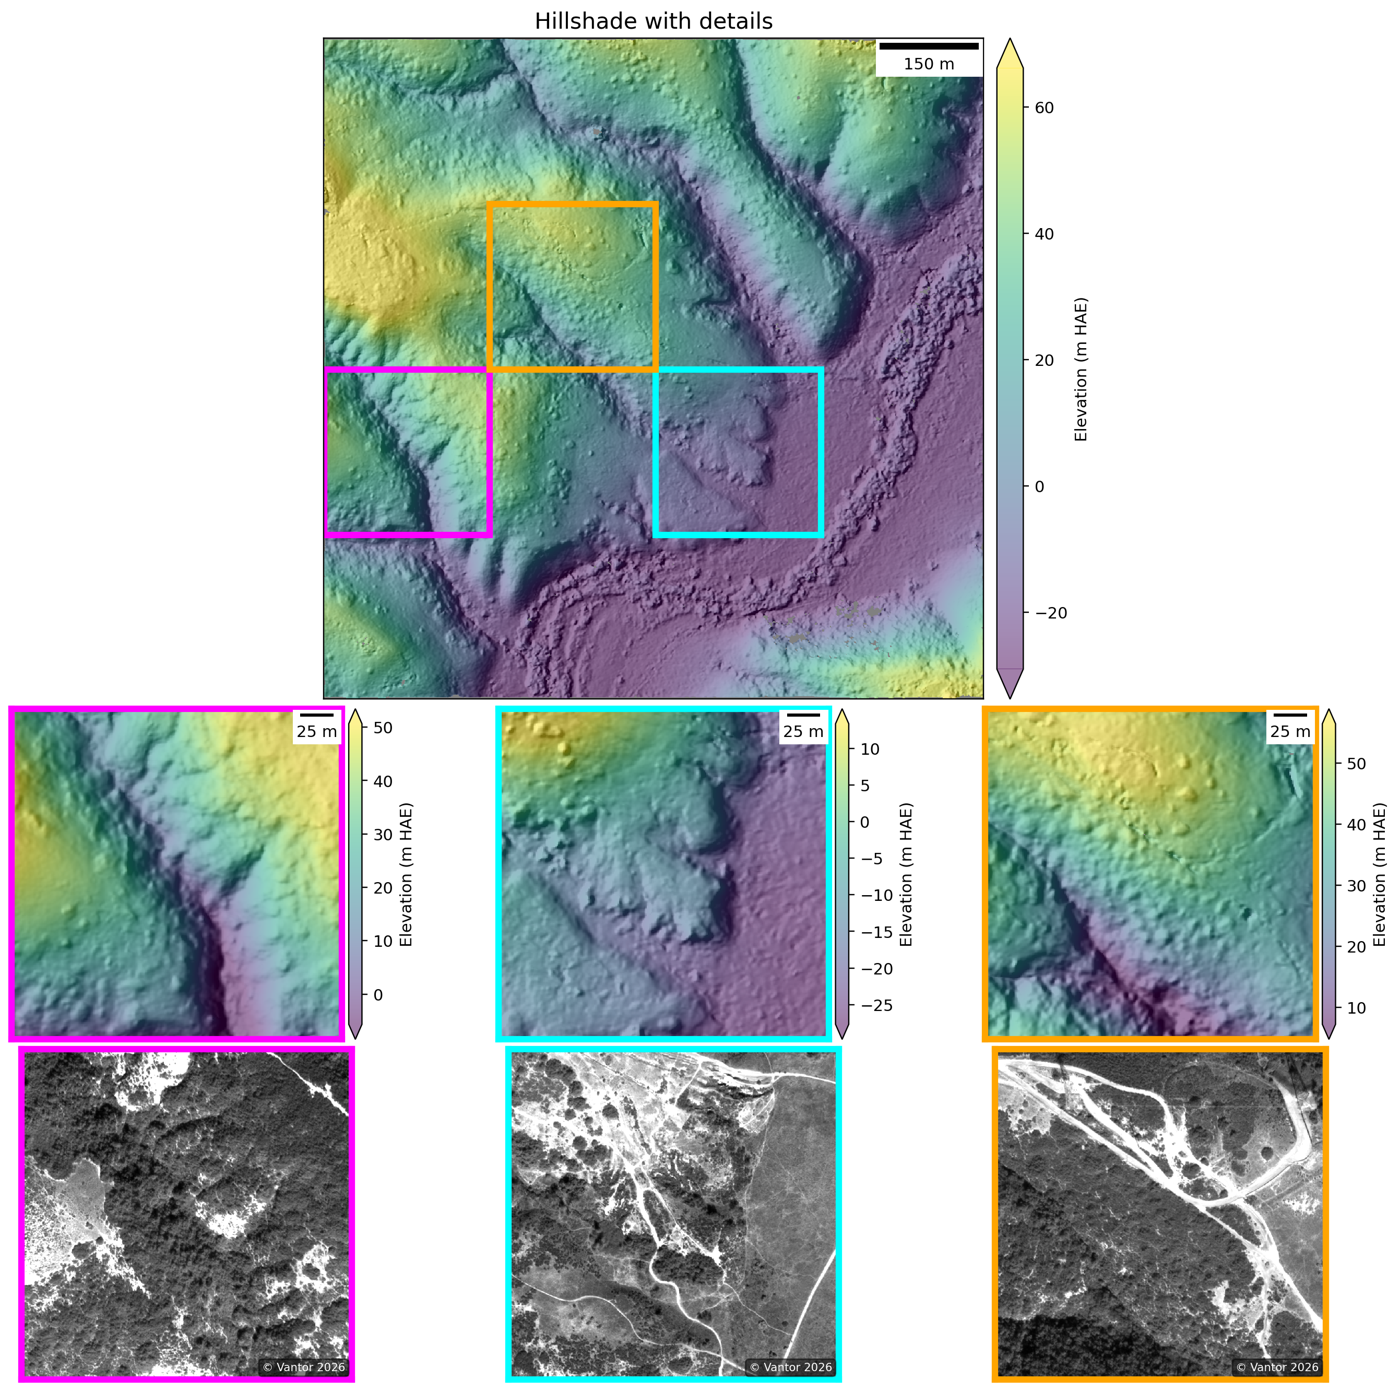

**Report figure 6.** A hillshade of the DEM, with zoomed details.

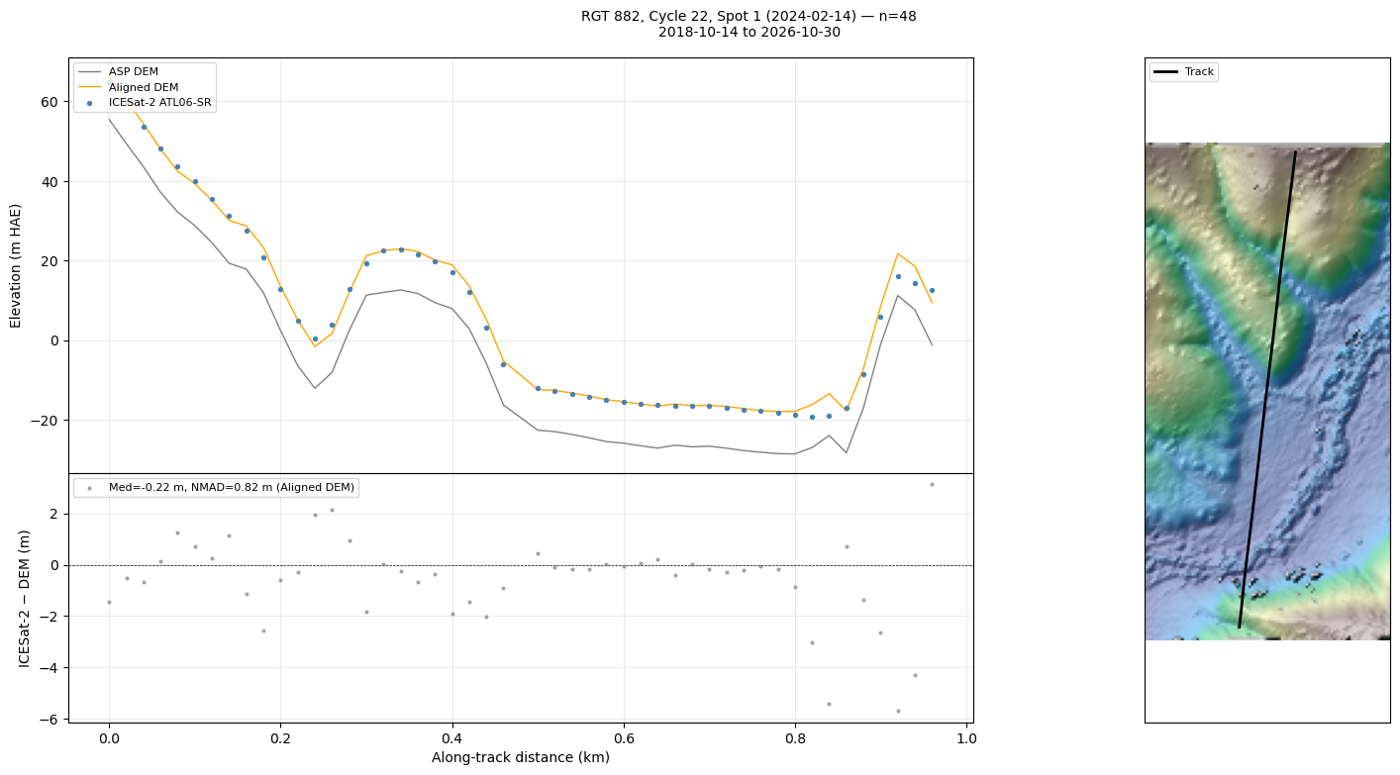

**Report figure 13.** The DEM along one ICESat-2 track, before and after the shift onto the ICESat-2 points, and the difference after it.

In [8]:
from utils import show_report_figures

FIGS = f"{DATA}/stereo/report_figures"
if Path(f"{DATA}/stereo/penasquitos_wv3_report.pdf").exists():
    print(f"{DATA}/stereo/penasquitos_wv3_report.pdf exists — skipping asp_report. Delete it to regenerate.")
else:
    reuse = "" if FRESH_ICESAT2 else f"--reuse-selections {SHIPPED_SELECTIONS}"
    run(f"""
        asp_report \
            --directory {DATA} \
            --stereo-directory stereo \
            --reference-dem {REF_DEM} \
            --subset-km 0.25 \
            --pc-align-min-points 150 \
            {reuse} \
            --figures-directory {FIGS} \
            --report-filename penasquitos_wv3_report.pdf
        """,
        log=f"{LOGS}/asp_report.log",
        label="Making the report",
    )

show_report_figures(FIGS)

### 📄 [Open the report (PDF)](../data/ucsd_penasquitos/stereo/penasquitos_wv3_report.pdf)

## 6. Download the results

The cell below puts the results into one zip file, `penasquitos_pair_results.zip`, in the top folder of the file explorer on the left. It includes:

- the `asp-plot` report, 
- the DEM,
- its hillshade,
- the map of triangulation error, 
- and the two orthorectified images (as 8-bit copies, to keep the zip small).

Each file is named by place, sensor and date, and the GeoTIFFs are Cloud Optimized GeoTIFFs with overviews, so they open quickly in QGIS, ArcGIS or any other GIS. A QGIS project file in the zip opens all of them at once. When the zip is ready, a notification at the bottom right points to it; right-click it in the explorer and choose **Download**.

> A few seconds.

In [9]:
from utils import zip_results

# Each result's file, its name in the zip (what it is, where, when, from what), and its kind.
NAME = "penasquitos_wv3_20141109_20150124"
zip_results(
    "../penasquitos_pair_results.zip",
    [
        (f"{DATA}/stereo/penasquitos_wv3_report.pdf", f"{NAME}_report.pdf", "pdf"),
        (f"{DATA}/stereo/run-DEM.tif", f"{NAME}_dem_1m.tif", "dem"),
        (f"{DATA}/stereo/run-DEM_hs.tif", f"{NAME}_dem_1m_hillshade.tif", "hillshade"),
        (f"{DATA}/stereo/run-IntersectionErr.tif", f"{NAME}_dem_1m_intersection_error.tif", "error"),
        (f"{DATA}/ortho/{SCENES[0]}.tif", "penasquitos_wv3_20141109_ortho_0.3m.tif", "image"),
        (f"{DATA}/ortho/{SCENES[1]}.tif", "penasquitos_wv3_20150124_ortho_0.3m.tif", "image"),
    ],
    title=NAME,
)

✅ **Zipping the results**: done in 1 s

### Results: `penasquitos_pair_results.zip` (25 MB, 7 files)

- `penasquitos_wv3_20141109_20150124_report.pdf`
- `penasquitos_wv3_20141109_20150124_dem_1m.tif`
- `penasquitos_wv3_20141109_20150124_dem_1m_hillshade.tif`
- `penasquitos_wv3_20141109_20150124_dem_1m_intersection_error.tif`
- `penasquitos_wv3_20141109_ortho_0.3m.tif`
- `penasquitos_wv3_20150124_ortho_0.3m.tif`
- `penasquitos_wv3_20141109_20150124.qgs`

To save it to your computer, right-click it in the file explorer on the left and choose **Download**. Unzip it and open `penasquitos_wv3_20141109_20150124.qgs` in QGIS to see everything at once.

### How to download it

The zip is in the **file explorer**, the panel on the left of the window with `data/`, `notebooks/` and the zip (if the panel is hidden, click the top icon in the bar at the far left). Right-click the zip there and choose **Download**; your browser then saves it like any download.

![The end of Tutorial 1: (1) the report link, (2) the results line, (3) the zip in the file explorer](../start/figures/launch-done.png)

The first time you right-click in the explorer, your browser may ask whether this page can see your clipboard. Click **Allow** or **Block**, whichever you prefer; the menu with **Download** works either way.

![The browser's clipboard question, with Block and Allow buttons](../start/figures/clipboard-prompt.png)

## What's next

→ [Tutorial 3: three images, blended](03_worldview_ucsd_blend.ipynb) adds a third image of the same area, runs stereo on all three pairs, and averages the three DEMs into one with fewer holes and less noise.